# Project Vyapaar - Business Data Treasure Hunt 🔎💰🚚

**Course:** Business Analytics (BBA, 3rd Year)
**Team:** ____________________ (fill in team name)

| Member | Lead role | What they led |
|---|---|---|
| Member 1: ________ | Data Analyst | Loading, data quality checks, cleaning log |
| Member 2: ________ | Business Analyst | Revenue, profit, discounts, customers |
| Member 3: ________ | Operations Analyst | Reviews, complaints, escalations, regions |
| Member 4: ________ | Visualisation & Strategy | Plotly charts, hidden mystery, management summary |

We split the lead roles but we discussed every finding together before writing it down.

### Our approach
**Explore → Question → Analyse → Verify → Visualise → Interpret → Recommend**

For every result we tried to answer the "**SO WHAT?**" question: *what happened, why does it matter, and what should management do?*

### Notebook map
1. **Stage 1: Data Detective** (can we trust the data?)
2. **Stage 2: Business Mystery** (categories, profit, discounts, customers)
3. **Stage 3: Customer & Operations Mystery** (order → delivery → review)
4. **Stage 4: OUR HIDDEN MYSTERY**
5. **Bonus: Marketing Mystery**
6. **Management Summary** (3 findings, 3 charts, 3 actions)

> **Note on data received:** the brief mentions six datasets. Our working folder had **orders, products, reviews and marketing** only. `customers.csv` and `delivery.csv` were not available to us. Where we needed them, we used proxies (explained below) and we have said clearly which statements are facts from the data and which are assumptions.

In [1]:
# Libraries we use
import os
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA = "data"
CHARTS = "charts"
os.makedirs(CHARTS, exist_ok=True)
os.makedirs(f"{DATA}/cleaned", exist_ok=True)

# Colours: grey for "normal", red for "problem", blue for the main measure
GREY = "#c3c2b7"
RED = "#e34948"
BLUE = "#2a78d6"
ORANGE = "#eb6834"


def lakh(x):
    # Indian style: 1 lakh = 1,00,000
    return f"₹{x / 1e5:,.2f} lakh"


def save_chart(fig, name):
    # Interactive HTML always works. PNG needs the kaleido package (+ Chrome), so we try it.
    fig.write_html(f"{CHARTS}/{name}.html", include_plotlyjs="cdn")
    try:
        fig.write_image(f"{CHARTS}/{name}.png", width=1100, height=600, scale=2)
    except Exception as e:
        print("PNG not saved (install kaleido if you need it):", e)

---
# Stage 1: Data Detective 🔎
Before we give any recommendation we need to know if the data can be trusted.

**Small thing we noticed while loading:** `orders.csv` and `reviews.csv` have a hidden "BOM" character at the start of the file, so the first column was being read as `﻿order_id` instead of `order_id`. We read them with `encoding="utf-8-sig"` to fix this.

**Another one:** pandas automatically treats the text `"None"` as a missing value. In `reviews.csv`, `"None"` in `complaint_category` actually means *"the customer did not complain"*. If we let pandas turn it into NaN we would lose that meaning, so we switch that default off for reviews.

In [2]:
orders = pd.read_csv(f"{DATA}/orders.csv", encoding="utf-8-sig")
products = pd.read_csv(f"{DATA}/products.csv")
reviews = pd.read_csv(f"{DATA}/reviews.csv", encoding="utf-8-sig",
                      keep_default_na=False, na_values=[""])   # keep "None" as text
marketing = pd.read_csv(f"{DATA}/marketing.csv")

# Check which of the six datasets we actually have
for f in ["customers.csv", "products.csv", "orders.csv", "delivery.csv", "reviews.csv", "marketing.csv"]:
    print(f"{f:15s}", "found" if os.path.exists(f"{DATA}/{f}") else "NOT FOUND in our data folder")

customers.csv   NOT FOUND in our data folder
products.csv    found
orders.csv      found
delivery.csv    NOT FOUND in our data folder
reviews.csv     found
marketing.csv   found


In [3]:
for name, d in [("orders", orders), ("products", products), ("reviews", reviews), ("marketing", marketing)]:
    print(f"{name}: {d.shape[0]} rows x {d.shape[1]} columns")
orders.head()

orders: 4001 rows x 14 columns
products: 121 rows x 7 columns
reviews: 4001 rows x 5 columns
marketing: 18 rows x 9 columns


,order_id,order_date,customer_id,product_id,quantity,unit_price_inr,discount_pct,revenue_inr,cost_inr,profit_inr,sales_channel,payment_method,campaign_id,region_at_order
0,O00001,2025-07-23,C0538,P035,1,"1,229.10",0.10,"1,106.19","1,007.86",98.33,Store,Debit Card,NaN,South
1,O00002,2025-11-22,C0015,P011,2,"6,025.06",0.00,"12,050.12","6,266.06","5,784.06",Store,COD,NaN,South
2,O00003,2025-04-16,C0158,P039,3,"1,643.71",0.20,"3,944.90","3,353.16",591.74,Marketplace,Debit Card,M01,East
3,O00004,2025-12-10,C0456,P101,1,"3,096.04",0.15,"2,631.63","1,609.94","1,021.69",Marketplace,COD,NaN,West
4,O00005,2025-03-20,C0003,P039,2,"1,643.71",0.00,"3,287.42","2,235.44","1,051.98",Website,UPI,NaN,North


In [4]:
products.head()

,product_id,product_name,category,subcategory,unit_cost_inr,list_price_inr,supplier
0,P001,Audio Item 001,Electronics,Audio,323.17,394.11,Aruna
1,P002,Footwear Item 002,Fashion,Footwear,324.66,559.76,Futura
2,P003,Fitness Item 003,Sports,Fitness,"3,265.04","5,266.19",Futura
3,P004,Sports Accessories Item 004,Sports,Sports Accessories,525.25,847.18,Futura
4,P005,Skin Care Item 005,Beauty,Skin Care,347.35,667.98,Futura


In [5]:
reviews.head()

,review_id,order_id,rating,complaint_category,escalated
0,R00001,O00001,3.00,Late delivery,0
1,R00002,O00002,4.00,None,0
2,R00003,O00003,2.00,Late delivery,1
3,R00004,O00004,4.00,None,0
4,R00005,O00005,4.00,None,0


In [6]:
marketing

,campaign_id,campaign_name,channel,start_date,end_date,spend_inr,leads,conversions,cost_per_conversion_inr
0,M01,Social Media Growth 01,Social Media,2025-01-01,2025-02-15,336420,1694,138,"2,437.83"
1,M02,Search Ads Growth 02,Search Ads,2025-01-21,2025-03-07,179161,3238,242,740.33
2,M03,Email Growth 03,Email,2025-02-10,2025-03-27,209553,2660,364,575.70
3,M04,Influencer Growth 04,Influencer,2025-03-02,2025-04-16,81295,4839,272,298.88
4,M05,Affiliate Growth 05,Affiliate,2025-03-22,2025-05-06,92961,4142,320,290.50
5,M06,Outdoor Growth 06,Outdoor,2025-04-11,2025-05-26,226626,2929,58,"3,907.34"
6,M07,Social Media Growth 07,Social Media,2025-05-01,2025-06-15,413129,5977,373,"1,107.58"
7,M08,Search Ads Growth 08,Search Ads,2025-05-21,2025-07-05,410288,1315,118,"3,477.02"
8,M09,Email Growth 09,Email,2025-06-10,2025-07-25,340036,3439,482,705.47
9,M10,Influencer Growth 10,Influencer,2025-06-30,2025-08-14,335202,5364,346,968.79


### 1.1 Data types
`order_date`, `start_date` and `end_date` came in as text, so we will convert them to dates. Everything else has a sensible type (numbers are numbers, IDs are text).

In [7]:
orders.dtypes

order_id               str
order_date             str
customer_id            str
product_id             str
quantity             int64
unit_price_inr     float64
discount_pct       float64
revenue_inr        float64
cost_inr           float64
profit_inr         float64
sales_channel          str
payment_method         str
campaign_id            str
region_at_order        str
dtype: object

### 1.2 Missing values

In [8]:
for name, d in [("orders", orders), ("products", products), ("reviews", reviews), ("marketing", marketing)]:
    miss = d.isna().sum()
    print(name, "->", miss[miss > 0].to_dict())

orders -> {'customer_id': 1, 'discount_pct': 1, 'campaign_id': 1472}
products -> {}
reviews -> {'rating': 1}
marketing -> {}


In [9]:
# Look at the actual rows with gaps (ignoring campaign_id for now)
orders[orders["customer_id"].isna() | orders["discount_pct"].isna()]

,order_id,order_date,customer_id,product_id,quantity,unit_price_inr,discount_pct,revenue_inr,cost_inr,profit_inr,sales_channel,payment_method,campaign_id,region_at_order
299,O00300,2025-01-05,NaN,P058,1,"3,762.37",0.05,"3,574.25","2,332.67","1,241.58",Website,COD,M16,East
777,O00778,2025-03-06,C0179,P074,1,"3,800.24",NaN,"2,660.17","2,584.16",76.01,App,Debit Card,M11,North


In [10]:
reviews[reviews["rating"].isna()]

,review_id,order_id,rating,complaint_category,escalated
1200,R01201,O01201,NaN,Late delivery,1


**What we think:**
- `campaign_id` is blank for **1,472 orders**. That is too many to be a typing error. It most likely means the order did not come through any campaign. We keep these as **"No campaign"**.
- `O00300` has no `customer_id`. The sale itself is real (product, price, revenue all present), so we keep it for sales/profit analysis and only leave it out of customer analysis.
- `O00778` has no `discount_pct`, but we can **work it out** from the other columns (see 1.6).
- `R01201` has no rating but it does tell us the customer had a late delivery and escalated. We keep the row and just leave it out of rating averages. We do **not** make up a rating.

### 1.3 Duplicates

In [11]:
print("Exact duplicate rows -> orders:", orders.duplicated().sum(),
      "| products:", products.duplicated().sum(),
      "| reviews:", reviews.duplicated().sum(),
      "| marketing:", marketing.duplicated().sum())

print("Duplicate IDs -> order_id:", orders["order_id"].duplicated().sum(),
      "| product_id:", products["product_id"].duplicated().sum(),
      "| review_id:", reviews["review_id"].duplicated().sum())

Exact duplicate rows -> orders: 1 | products: 1 | reviews: 1 | marketing: 0
Duplicate IDs -> order_id: 1 | product_id: 1 | review_id: 1


In [12]:
pd.concat([orders[orders.duplicated(keep=False)],
           products[products.duplicated(keep=False)].assign(table="products")], ignore_index=True).dropna(axis=1, how="all")

,order_id,order_date,customer_id,product_id,quantity,unit_price_inr,discount_pct,revenue_inr,cost_inr,profit_inr,sales_channel,payment_method,campaign_id,region_at_order,product_name,category,subcategory,unit_cost_inr,list_price_inr,supplier,table
0,O00501,2025-08-06,C0202,P069,1.00,"6,706.13",0.00,"6,706.13","3,487.19","3,218.94",Website,Credit Card,M14,South,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,O00501,2025-08-06,C0202,P069,1.00,"6,706.13",0.00,"6,706.13","3,487.19","3,218.94",Website,Credit Card,M14,South,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,P040,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Desk Accessories Item 040,Office Supplies,Desk Accessories,"3,270.76","5,031.94",DigiKart,products
3,NaN,NaN,NaN,P040,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Desk Accessories Item 040,Office Supplies,Desk Accessories,"3,270.76","5,031.94",DigiKart,products


Each duplicate is a **100% identical copy** (same ID and same values), so it is a double entry, not a second sale.

The product duplicate (`P040`) is the dangerous one: when we join orders to products, every `P040` order would match twice and its revenue would be **double counted**. So we must remove it **before** merging.

### 1.4 Inconsistent categories and spellings

In [13]:
print(products["category"].value_counts(), "\n")
print(orders["sales_channel"].value_counts())

category
Beauty             25
Electronics        24
Sports             20
Home & Kitchen     20
Fashion            16
Office Supplies    15
Electronic          1
Name: count, dtype: int64 

sales_channel
App            1346
Website        1259
Store           878
Marketplace     517
web site          1
Name: count, dtype: int64


In [14]:
# Which products look wrongly labelled?
products[(products["category"] == "Electronic") | (products["subcategory"] == "skin care")]

,product_id,product_name,category,subcategory,unit_cost_inr,list_price_inr,supplier
10,P011,Hair Care Item 011,Electronic,Hair Care,"3,133.03","6,025.06",Crescent
73,P074,Small Appliances Item 074,Home & Kitchen,skin care,"2,584.16","3,800.24",BharatWorks


Two products look wrong:
- `P011` is called **"Hair Care Item 011"**, subcategory Hair Care, but category says **"Electronic"** (also a spelling variant of "Electronics").
- `P074` is called **"Small Appliances Item 074"** in Home & Kitchen, but subcategory says **"skin care"**.

We did not want to "fix" these just based on the name, so we looked for more evidence. We noticed every category has its own fixed **mark-up** (list price ÷ unit cost). If that pattern holds, it tells us which category a product really belongs to:

In [15]:
products["markup"] = (products["list_price_inr"] / products["unit_cost_inr"]).round(3)
print(products.groupby("category")["markup"].agg(["min", "max", "count"]))
print()
print(products.loc[products["product_id"].isin(["P011", "P074"]), ["product_id", "product_name", "category", "subcategory", "markup"]])

                 min  max  count
category                        
Beauty          1.92 1.92     25
Electronic      1.92 1.92      1
Electronics     1.22 1.22     24
Fashion         1.72 1.72     16
Home & Kitchen  1.47 1.47     20
Office Supplies 1.54 1.54     15
Sports          1.61 1.61     20

   product_id               product_name        category subcategory  markup
10       P011         Hair Care Item 011      Electronic   Hair Care    1.92
73       P074  Small Appliances Item 074  Home & Kitchen   skin care    1.47


**Evidence:** every Beauty product has a mark-up of exactly **1.923** and every Home & Kitchen product **1.471**. `P011` has 1.923 (Beauty pricing) and `P074` has 1.471 (Home & Kitchen pricing). Together with the product names, we are confident:
- `P011` → category **Beauty** (subcategory Hair Care stays)
- `P074` → subcategory **Small Appliances** (category Home & Kitchen stays)

`"web site"` (1 order) is just a spelling variant of **"Website"**.

### 1.5 Do the money columns add up?
If revenue, cost and profit are wrong, nothing else matters. We re-calculated them from scratch:
- revenue = quantity × unit price × (1 − discount)
- cost = quantity × product unit cost
- profit = revenue − cost

In [16]:
chk = orders.merge(products.drop_duplicates()[["product_id", "unit_cost_inr", "list_price_inr"]], on="product_id", how="left")
chk["rev_calc"] = chk["quantity"] * chk["unit_price_inr"] * (1 - chk["discount_pct"])
chk["cost_calc"] = chk["quantity"] * chk["unit_cost_inr"]

print("Orders where selling price differs from product list price:", (abs(chk["unit_price_inr"] - chk["list_price_inr"]) > 0.01).sum())
print("Orders where revenue doesn't match our calculation:", (abs(chk["rev_calc"] - chk["revenue_inr"]) > 1).sum())
print("Orders where cost doesn't match:", (abs(chk["cost_calc"] - chk["cost_inr"]) > 1).sum())
print("Orders where profit != revenue - cost:", (abs(chk["revenue_inr"] - chk["cost_inr"] - chk["profit_inr"]) > 1).sum())

Orders where selling price differs from product list price: 0
Orders where revenue doesn't match our calculation: 0
Orders where cost doesn't match: 0
Orders where profit != revenue - cost: 0


All the money columns are internally consistent. 👍 So the financial numbers can be trusted.

### 1.6 Rebuilding the missing discount
Because revenue = qty × price × (1 − discount), the missing discount for `O00778` is simply `1 − revenue / (qty × price)`:

In [17]:
row = orders[orders["discount_pct"].isna()].iloc[0]
derived = 1 - row["revenue_inr"] / (row["quantity"] * row["unit_price_inr"])
print(row["order_id"], "-> derived discount =", round(derived, 4))
print("Discount levels used in the business:", sorted(orders["discount_pct"].dropna().unique()))

O00778 -> derived discount = 0.3
Discount levels used in the business: [np.float64(0.0), np.float64(0.05), np.float64(0.1), np.float64(0.15), np.float64(0.2), np.float64(0.3), np.float64(0.4)]


The derived value is **0.30**, which is exactly one of the seven discount levels the company uses (0%, 5%, 10%, 15%, 20%, 30%, 40%). So this is not a guess, it is the real discount.

### 1.7 Suspicious values and outliers

In [18]:
print("Order dates:", orders["order_date"].min(), "to", orders["order_date"].max(),
      "| bad dates:", pd.to_datetime(orders["order_date"], format="%Y-%m-%d", errors="coerce").isna().sum())
print("Quantity range:", orders["quantity"].min(), "-", orders["quantity"].max())
print("Ratings:", sorted(reviews["rating"].dropna().unique()))
print("Orders with NEGATIVE profit:", (orders["profit_inr"] < 0).sum())
orders["profit_inr"].describe()

Order dates: 2025-01-01 to 2025-12-31 | bad dates: 0
Quantity range: 1 - 5
Ratings: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
Orders with NEGATIVE profit: 313


count    4,001.00
mean     1,199.99
std      1,583.24
min     -2,409.56
25%        216.49
50%        665.94
75%      1,660.62
max     14,460.15
Name: profit_inr, dtype: float64

**313 orders lose money.** Our first reaction was "data error?" but section 1.5 proved the maths is correct. These are real sales where the discount was bigger than the product's margin. **This is not an error, it is a business finding**, so we keep them (see Stage 2).

The highest revenue orders (up to ₹30,125) are just expensive products bought in quantity 5. Nothing impossible, so we kept all outliers.

### 1.8 Do the tables link properly?

In [19]:
print("Orders with a product not in products table:", (~orders["product_id"].isin(products["product_id"])).sum())
print("Reviews whose order is missing:", (~reviews["order_id"].isin(orders["order_id"])).sum())
print("Orders with no review:", (~orders["order_id"].isin(reviews["order_id"])).sum())
print("Campaign IDs not in marketing table:", (~orders["campaign_id"].dropna().isin(marketing["campaign_id"])).sum())

# We don't have customers.csv. Can region_at_order stand in for the customer's region?
print("Customers who ordered from more than one region:",
      (orders.dropna(subset=["customer_id"]).groupby("customer_id")["region_at_order"].nunique() > 1).sum())

Orders with a product not in products table: 0
Reviews whose order is missing: 0
Orders with no review: 0
Campaign IDs not in marketing table: 0
Customers who ordered from more than one region: 0


All the joins work and every order has exactly one review. Also, **every customer always orders from the same region**, so we can safely use `region_at_order` as the customer's region in place of the missing customers file.

In [20]:
# Is each campaign-tagged order actually inside that campaign's dates?
tmp = orders.dropna(subset=["campaign_id"]).merge(marketing[["campaign_id", "start_date", "end_date"]], on="campaign_id")
d, s, e = pd.to_datetime(tmp["order_date"]), pd.to_datetime(tmp["start_date"]), pd.to_datetime(tmp["end_date"])
print("Campaign-tagged orders:", len(tmp))
print("  placed BEFORE the campaign started:", (d < s).sum())
print("  placed DURING the campaign:", ((d >= s) & (d <= e)).sum())
print("  placed AFTER the campaign ended:", (d > e).sum())

# Store orders with 'Late delivery' complaints?
st = orders[orders["sales_channel"] == "Store"].merge(reviews, on="order_id")
print("\nStore orders with a 'Late delivery' complaint:", (st["complaint_category"] == "Late delivery").sum(), "of", len(st))

Campaign-tagged orders: 2529
  placed BEFORE the campaign started: 1216
  placed DURING the campaign: 283
  placed AFTER the campaign ended: 1030

Store orders with a 'Late delivery' complaint: 179 of 878


🚩 **Two red flags we are NOT deleting:**
1. **Almost half of the campaign-tagged orders happened before the campaign even started.** That is impossible if the tag means "this campaign brought the order". We keep the column but **do not use it to calculate campaign returns**. We dig into this in our Hidden Mystery.
2. **Store orders get "Late delivery" complaints** (179 of 878). A store purchase is normally taken home on the spot. Maybe Vyapaar delivers store orders to homes, or the channel label is wrong. We need `delivery.csv` to confirm, so we just flag it.

### 1.9 Cleaning actions
Now we apply the fixes and keep a **cleaning log** (Problem → Action → Reason).

In [21]:
orders_c = orders.copy()
products_c = products.drop(columns="markup").copy()
reviews_c = reviews.copy()
marketing_c = marketing.copy()

# 1. Remove exact duplicate rows
orders_c = orders_c.drop_duplicates()
products_c = products_c.drop_duplicates()
reviews_c = reviews_c.drop_duplicates()

# 2. Fix product labels (backed by mark-up evidence)
products_c.loc[products_c["product_id"] == "P011", "category"] = "Beauty"
products_c.loc[products_c["product_id"] == "P074", "subcategory"] = "Small Appliances"

# 3. Standardise sales channel spelling
orders_c["sales_channel"] = orders_c["sales_channel"].replace({"web site": "Website"})

# 4. Rebuild missing discount from revenue
gap = orders_c["discount_pct"].isna()
orders_c.loc[gap, "discount_pct"] = (1 - orders_c.loc[gap, "revenue_inr"] /
                                     (orders_c.loc[gap, "quantity"] * orders_c.loc[gap, "unit_price_inr"])).round(2)

# 5. Label missing customer and missing campaign (keep the rows!)
orders_c["customer_id"] = orders_c["customer_id"].fillna("Unknown")
orders_c["campaign_id"] = orders_c["campaign_id"].fillna("No campaign")

# 6. Convert text to proper dates
orders_c["order_date"] = pd.to_datetime(orders_c["order_date"])
marketing_c["start_date"] = pd.to_datetime(marketing_c["start_date"])
marketing_c["end_date"] = pd.to_datetime(marketing_c["end_date"])

print("orders:", len(orders), "->", len(orders_c), "| products:", len(products), "->", len(products_c),
      "| reviews:", len(reviews), "->", len(reviews_c))

orders: 4001 -> 4000 | products: 121 -> 120 | reviews: 4001 -> 4000


In [22]:
cleaning_log = pd.DataFrame([
    ["orders.csv & reviews.csv first column read as '\\ufefforder_id'", "Read files with encoding='utf-8-sig'", "Hidden BOM character in file; otherwise joins on order_id fail"],
    ["'None' in complaint_category turned into NaN by pandas (2,640 rows)", "Read with keep_default_na=False", "'None' means 'no complaint', which is real information"],
    ["Order O00501 appears twice, identical", "Removed 1 copy", "Double entry; would overstate revenue by ₹6,706"],
    ["Review R00334 appears twice, identical", "Removed 1 copy", "One review per order"],
    ["Product P040 appears twice, identical", "Removed 1 copy BEFORE merging", "Would double count all P040 orders in the join"],
    ["P011 'Hair Care Item 011' has category 'Electronic'", "Changed category to 'Beauty'", "Name + subcategory say Hair Care; mark-up 1.923 = Beauty pricing"],
    ["P074 'Small Appliances Item 074' has subcategory 'skin care'", "Changed subcategory to 'Small Appliances'", "Name says Small Appliances; mark-up 1.471 = Home & Kitchen pricing"],
    ["Sales channel 'web site' (1 order)", "Changed to 'Website'", "Spelling variant of the same channel"],
    ["O00778 missing discount_pct", "Derived 1 - revenue/(qty x price) = 0.30", "Calculated from real data, matches a standard discount level; not a guess"],
    ["O00300 missing customer_id", "Kept order, customer = 'Unknown'", "Sale is real; excluded only from customer analysis"],
    ["R01201 missing rating", "Kept row, left rating blank", "Complaint and escalation info is still useful; we don't invent ratings"],
    ["campaign_id blank on 1,472 orders", "Labelled 'No campaign'", "Blank = order not linked to a campaign, not an error"],
    ["313 orders with negative profit", "Kept", "Maths checked and correct; losses come from deep discounts (business finding)"],
    ["order_date / campaign dates stored as text", "Converted to datetime", "Needed for monthly and campaign-window analysis"],
    ["89% of campaign-tagged orders fall outside the campaign dates", "Kept but NOT used for campaign returns", "Tag cannot mean 'this campaign caused the order' (see Hidden Mystery)"],
    ["Store orders with 'Late delivery' complaints (179)", "Kept, flagged", "Need delivery.csv to confirm whether store orders are home-delivered"],
    ["customers.csv and delivery.csv not in our folder", "Used region_at_order + review complaints as proxies", "Every customer orders from only one region, so region_at_order is a safe stand-in"],
], columns=["Problem found", "Action taken", "Reason"])
cleaning_log.index = cleaning_log.index + 1
cleaning_log.to_csv(f"{DATA}/cleaned/cleaning_log.csv", index_label="#")
cleaning_log

,Problem found,Action taken,Reason
1,orders.csv & reviews.csv first column read as ...,Read files with encoding='utf-8-sig',Hidden BOM character in file; otherwise joins ...
2,'None' in complaint_category turned into NaN b...,Read with keep_default_na=False,"'None' means 'no complaint', which is real inf..."
3,"Order O00501 appears twice, identical",Removed 1 copy,"Double entry; would overstate revenue by ₹6,706"
4,"Review R00334 appears twice, identical",Removed 1 copy,One review per order
5,"Product P040 appears twice, identical",Removed 1 copy BEFORE merging,Would double count all P040 orders in the join
6,P011 'Hair Care Item 011' has category 'Electr...,Changed category to 'Beauty',Name + subcategory say Hair Care; mark-up 1.92...
7,P074 'Small Appliances Item 074' has subcatego...,Changed subcategory to 'Small Appliances',Name says Small Appliances; mark-up 1.471 = Ho...
8,Sales channel 'web site' (1 order),Changed to 'Website',Spelling variant of the same channel
9,O00778 missing discount_pct,Derived 1 - revenue/(qty x price) = 0.30,"Calculated from real data, matches a standard ..."
10,O00300 missing customer_id,"Kept order, customer = 'Unknown'",Sale is real; excluded only from customer anal...


### 1.10 One master table
We join everything on the ID fields: **orders → products → reviews**. Then we add a few helper columns.

In [23]:
df = (orders_c
      .merge(products_c[["product_id", "product_name", "category", "subcategory", "supplier", "list_price_inr", "unit_cost_inr"]],
             on="product_id", how="left", validate="many_to_one")
      .merge(reviews_c, on="order_id", how="left", validate="one_to_one"))

df["margin"] = df["profit_inr"] / df["revenue_inr"]
df["month"] = df["order_date"].dt.month
df["complained"] = df["complaint_category"] != "None"
df["late_complaint"] = df["complaint_category"] == "Late delivery"
df["loss_order"] = df["profit_inr"] < 0

print(df.shape, "| revenue check:", lakh(df["revenue_inr"].sum()))
df.to_csv(f"{DATA}/cleaned/vyapaar_master_clean.csv", index=False)
df.head()

(4000, 29) | revenue check: ₹175.95 lakh


,order_id,order_date,customer_id,product_id,quantity,unit_price_inr,discount_pct,revenue_inr,cost_inr,profit_inr,sales_channel,payment_method,campaign_id,region_at_order,product_name,category,subcategory,supplier,list_price_inr,unit_cost_inr,review_id,rating,complaint_category,escalated,margin,month,complained,late_complaint,loss_order
0,O00001,2025-07-23,C0538,P035,1,"1,229.10",0.10,"1,106.19","1,007.86",98.33,Store,Debit Card,No campaign,South,Audio Item 035,Electronics,Audio,Futura,"1,229.10","1,007.86",R00001,3.00,Late delivery,0,0.09,7,True,True,False
1,O00002,2025-11-22,C0015,P011,2,"6,025.06",0.00,"12,050.12","6,266.06","5,784.06",Store,COD,No campaign,South,Hair Care Item 011,Beauty,Hair Care,Crescent,"6,025.06","3,133.03",R00002,4.00,None,0,0.48,11,False,False,False
2,O00003,2025-04-16,C0158,P039,3,"1,643.71",0.20,"3,944.90","3,353.16",591.74,Marketplace,Debit Card,M01,East,Small Appliances Item 039,Home & Kitchen,Small Appliances,Aruna,"1,643.71","1,117.72",R00003,2.00,Late delivery,1,0.15,4,True,True,False
3,O00004,2025-12-10,C0456,P101,1,"3,096.04",0.15,"2,631.63","1,609.94","1,021.69",Marketplace,COD,No campaign,West,Hair Care Item 101,Beauty,Hair Care,DigiKart,"3,096.04","1,609.94",R00004,4.00,None,0,0.39,12,False,False,False
4,O00005,2025-03-20,C0003,P039,2,"1,643.71",0.00,"3,287.42","2,235.44","1,051.98",Website,UPI,No campaign,North,Small Appliances Item 039,Home & Kitchen,Small Appliances,Aruna,"1,643.71","1,117.72",R00005,4.00,None,0,0.32,3,False,False,False


✅ **Stage 1 verdict:** the transaction and money data is **trustworthy** after a few small fixes. The one field we **cannot** trust is the campaign tag on orders.

---
# Stage 2: The Business Mystery 💰
### 2.1 The big picture

In [24]:
total_rev = df["revenue_inr"].sum()
total_profit = df["profit_inr"].sum()
print("Orders:", len(df), "| Customers:", df.loc[df["customer_id"] != "Unknown", "customer_id"].nunique(), "| Products:", df["product_id"].nunique())
print("Revenue:", lakh(total_rev))
print("Gross profit (revenue - product cost):", lakh(total_profit))
print("Gross margin:", f"{total_profit / total_rev:.1%}")

Orders: 4000 | Customers: 599 | Products: 120
Revenue: ₹175.95 lakh
Gross profit (revenue - product cost): ₹47.98 lakh
Gross margin: 27.3%


In [25]:
monthly = df.groupby("month").agg(revenue=("revenue_inr", "sum"), profit=("profit_inr", "sum"), orders=("order_id", "count"))
monthly["margin_%"] = (monthly["profit"] / monthly["revenue"] * 100).round(1)
monthly

,revenue,profit,orders,margin_%
month,,,,
1,"1,552,566.22","413,556.77",325,26.60
2,"1,324,069.96","363,873.85",295,27.50
3,"1,699,993.07","478,182.94",383,28.10
4,"1,453,862.72","399,891.32",310,27.50
5,"1,317,569.17","331,610.84",329,25.20
6,"1,562,035.74","416,048.83",357,26.60
7,"1,440,499.68","384,384.58",339,26.70
8,"1,518,165.59","429,740.51",349,28.30
9,"1,434,133.92","380,749.23",326,26.50


Revenue is steady at roughly ₹13-17 lakh every month with a margin of 25-28%. No big seasonal spikes, so we focus on **where** the money comes from rather than **when**.

### 2.2 Does high revenue mean high profit? (categories)

In [26]:
cat = df.groupby("category").agg(orders=("order_id", "count"),
                                 revenue=("revenue_inr", "sum"),
                                 profit=("profit_inr", "sum"),
                                 avg_discount=("discount_pct", "mean"),
                                 loss_orders=("loss_order", "sum"))
cat["avg_discount"] = cat["avg_discount"] * 100
cat = cat.rename(columns={"avg_discount": "avg_discount_%"})
cat["margin_%"] = cat["profit"] / cat["revenue"] * 100
cat["revenue_share_%"] = cat["revenue"] / cat["revenue"].sum() * 100
cat["profit_share_%"] = cat["profit"] / cat["profit"].sum() * 100
cat = cat.sort_values("revenue", ascending=False)
cat.round(1)

,orders,revenue,profit,avg_discount_%,loss_orders,margin_%,revenue_share_%,profit_share_%
category,,,,,,,,
Beauty,822,"5,270,516.40","2,143,754.20",12.30,0,40.70,30.00,44.70
Sports,674,"2,985,703.00","866,630.10",12.90,30,29.00,17.00,18.10
Home & Kitchen,682,"2,791,150.00","633,071.70",12.30,28,22.70,15.90,13.20
Electronics,809,"2,555,199.70","154,694.90",12.80,237,6.10,14.50,3.20
Office Supplies,472,"2,153,940.50","551,362.70",12.30,18,25.60,12.20,11.50
Fashion,541,"1,838,507.90","448,445.30",22.80,0,24.40,10.40,9.30


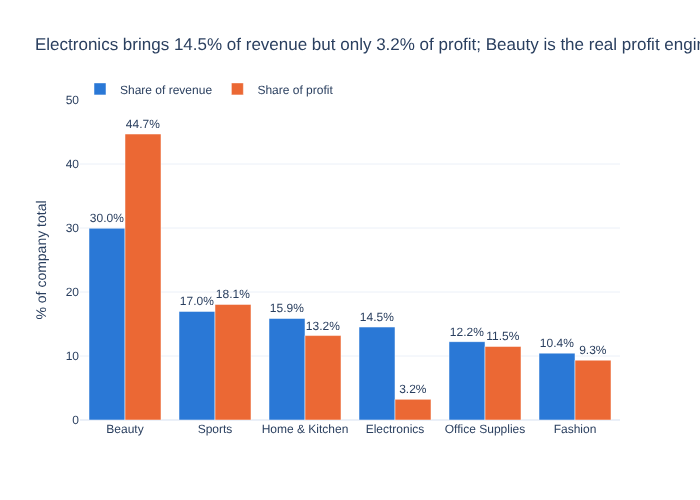

In [27]:
# CHART 1: revenue share vs profit share by category
c1 = cat.reset_index().melt(id_vars="category", value_vars=["revenue_share_%", "profit_share_%"],
                            var_name="measure", value_name="share")
c1["measure"] = c1["measure"].map({"revenue_share_%": "Share of revenue", "profit_share_%": "Share of profit"})

fig1 = px.bar(c1, x="category", y="share", color="measure", barmode="group", text=c1["share"].round(1).astype(str) + "%",
              color_discrete_map={"Share of revenue": BLUE, "Share of profit": ORANGE},
              title="Electronics brings 14.5% of revenue but only 3.2% of profit; Beauty is the real profit engine",
              labels={"share": "% of company total", "category": "", "measure": ""},
              template="plotly_white")
fig1.update_traces(textposition="outside")
fig1.update_layout(legend=dict(orientation="h", y=1.08, x=0), yaxis_range=[0, 50])
save_chart(fig1, "chart1_category_revenue_vs_profit")
fig1.show()

In [28]:
# Drill down: margin by subcategory (lowest first)
sub = df.groupby(["category", "subcategory"]).agg(revenue=("revenue_inr", "sum"), profit=("profit_inr", "sum"))
sub["margin_%"] = (sub["profit"] / sub["revenue"] * 100).round(1)
sub.sort_values("margin_%").head(6)

revenue     profit  margin_%
category       subcategory                                         
Electronics    Audio                503,853.63  23,341.00      4.60
               Smart Devices      1,585,456.17  97,524.52      6.20
               Mobile Accessories   465,889.90  33,829.35      7.30
Home & Kitchen Small Appliances     907,892.00 196,652.06     21.70
               Cookware           1,081,586.51 244,447.60     22.60
Fashion        Men                1,003,221.20 237,560.60     23.70

**So what?**
- **Beauty** is 30% of revenue but **45% of profit** (41% margin). It is our best business.
- **Electronics** is the 4th biggest category by revenue but makes only **6.1% margin**, and **237 of its 809 orders lost money**. All three Electronics subcategories (Audio, Smart Devices, Mobile Accessories) are the bottom three of the whole company.
- *Why?* The mark-up table in Stage 1 explains it: Electronics is priced at only **1.22× cost** (18% margin before any discount), while Beauty is 1.92×. Electronics simply has **no room for discounts**, yet it gets the same ~13% average discount as everything else.

### 2.3 Are discounts helping the business?

In [29]:
disc = df.groupby("discount_pct").agg(orders=("order_id", "count"),
                                      avg_quantity=("quantity", "mean"),
                                      revenue=("revenue_inr", "sum"),
                                      profit=("profit_inr", "sum"),
                                      avg_profit_per_order=("profit_inr", "mean"),
                                      pct_loss_orders=("loss_order", "mean"))
disc["margin_%"] = disc["profit"] / disc["revenue"] * 100
disc["pct_loss_orders"] = disc["pct_loss_orders"] * 100
disc.index = (disc.index * 100).astype(int).astype(str) + "%"
disc.round(2)

,orders,avg_quantity,revenue,profit,avg_profit_per_order,pct_loss_orders,margin_%
discount_pct,,,,,,,
0%,698,1.77,"3,562,855.47","1,336,837.67","1,915.24",0.00,37.52
5%,633,1.75,"2,947,011.61","983,224.09","1,553.28",0.00,33.36
10%,830,1.83,"3,985,593.04","1,181,223.87","1,423.16",0.00,29.64
15%,548,1.79,"2,510,291.23","658,667.65","1,201.95",0.00,26.24
20%,557,1.76,"2,258,136.82","469,981.24",843.77,22.80,20.81
30%,444,1.78,"1,513,937.17","177,639.68",400.09,16.22,11.73
40%,290,1.69,"817,192.12","-9,615.34",-33.16,39.31,-1.18


In [30]:
print("Correlation between discount and quantity bought:", round(df["discount_pct"].corr(df["quantity"]), 3))

Correlation between discount and quantity bought: -0.012


This is the key result. If discounts were working, customers would buy **more units** when the discount is bigger. They don't:
- Average quantity is **1.77 units at 0% discount** and **1.69 units at 40% discount**. The correlation is basically zero (−0.01).
- Meanwhile profit per order falls from **₹1,915 at 0%** to **−₹33 at 40%**. At 40% discount the company **loses money on average**.

So the discount is mostly a price cut for customers who would have bought anyway. Now let's see it by category:

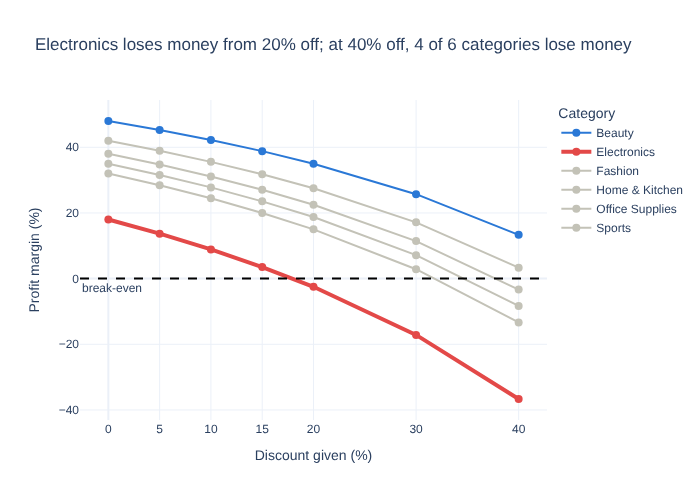

In [31]:
# CHART 2: margin at each discount level, by category
c2 = df.groupby(["category", "discount_pct"]).agg(revenue=("revenue_inr", "sum"), profit=("profit_inr", "sum")).reset_index()
c2["margin_%"] = c2["profit"] / c2["revenue"] * 100
c2["discount_%"] = c2["discount_pct"] * 100

colour_map = {c: GREY for c in c2["category"].unique()}
colour_map["Electronics"] = RED
colour_map["Beauty"] = BLUE

fig2 = px.line(c2, x="discount_%", y="margin_%", color="category", markers=True,
               color_discrete_map=colour_map,
               title="Electronics loses money from 20% off; at 40% off, 4 of 6 categories lose money",
               labels={"discount_%": "Discount given (%)", "margin_%": "Profit margin (%)", "category": "Category"},
               template="plotly_white")
fig2.update_traces(line=dict(width=2), marker=dict(size=8))
fig2.update_traces(selector=dict(name="Electronics"), line=dict(width=4))
fig2.add_hline(y=0, line_dash="dash", line_color="black", annotation_text="break-even", annotation_position="bottom left")
fig2.update_xaxes(tickvals=[0, 5, 10, 15, 20, 30, 40])
save_chart(fig2, "chart2_discount_vs_margin")
fig2.show()

In [32]:
# Where are the loss-making orders?
pd.crosstab(df.loc[df["loss_order"], "category"], (df.loc[df["loss_order"], "discount_pct"] * 100).astype(int).astype(str) + "%", margins=True)

discount_pct,20%,30%,40%,All
category,,,,
Electronics,127,72,38,237
Home & Kitchen,0,0,28,28
Office Supplies,0,0,18,18
Sports,0,0,30,30
All,127,72,114,313


In [33]:
# What if Electronics discounts were capped at 10%?
# ASSUMPTION: customers still buy the same quantity (supported by the flat quantity result above)
elec = df[df["category"] == "Electronics"].copy()
elec["capped_disc"] = elec["discount_pct"].clip(upper=0.10)
elec["capped_profit"] = elec["quantity"] * elec["unit_price_inr"] * (1 - elec["capped_disc"]) - elec["cost_inr"]
print("Electronics profit now:", lakh(elec["profit_inr"].sum()))
print("Electronics profit with a 10% cap:", lakh(elec["capped_profit"].sum()))
print("Extra profit:", lakh(elec["capped_profit"].sum() - elec["profit_inr"].sum()))

Electronics profit now: ₹1.55 lakh
Electronics profit with a 10% cap: ₹3.06 lakh
Extra profit: ₹1.51 lakh


In [34]:
# Fashion gets far more deep discounts than the others
fashion_mix = pd.crosstab(df["category"], df["discount_pct"] >= 0.30, normalize="index") * 100
fashion_mix.columns = ["% orders below 30% discount", "% orders at 30-40% discount"]
fashion_mix.round(1).sort_values("% orders at 30-40% discount", ascending=False)

,% orders below 30% discount,% orders at 30-40% discount
category,,
Fashion,45.30,54.70
Sports,86.20,13.80
Electronics,86.40,13.60
Home & Kitchen,87.20,12.80
Beauty,88.30,11.70
Office Supplies,89.00,11.00


In [35]:
deep = df[df["discount_pct"] >= 0.30]
print("Orders at 30-40% discount:", len(deep), f"({len(deep) / len(df):.0%} of orders)")
print("Their share of revenue:", f"{deep['revenue_inr'].sum() / total_rev:.1%}", "| share of profit:", f"{deep['profit_inr'].sum() / total_profit:.1%}")
print("Total discount given away in the year:", lakh((df["quantity"] * df["unit_price_inr"]).sum() - total_rev))

Orders at 30-40% discount: 734 (18% of orders)
Their share of revenue: 13.2% | share of profit: 3.5%
Total discount given away in the year: ₹27.99 lakh


**So what? (discounts)**
- The evidence does **not** support the current discount strategy. Bigger discounts do not make people buy more; they only shrink the margin.
- Orders at 30-40% discount are **18% of orders and 13% of revenue but only 3.5% of profit**.
- The company gave away **₹28 lakh in discounts** in one year. That is more than half of the total gross profit (₹48 lakh).
- **Electronics** should never go above 15% (it is negative at 20%+). Capping it at 10% would add about **₹1.5 lakh** profit in a year, roughly doubling Electronics profit, *assuming* volumes stay the same.
- **Fashion** is a "clearance" category: **55% of Fashion orders are at 30-40% off**. It survives only because Fashion's mark-up is high (1.72×).

*Fact vs assumption:* the margin numbers are facts. The "same quantity after a cap" is an assumption, but it is backed by the data showing quantity does not react to discount.

### 2.4 Customers: who deserves management attention?
**Our definition of a high-value customer:** a customer in the **top 10% by total gross profit** generated in 2025. We use profit, not revenue, because Stage 2 showed that revenue can hide loss-making orders.

In [36]:
cust = (df[df["customer_id"] != "Unknown"]
        .groupby("customer_id")
        .agg(orders=("order_id", "count"), revenue=("revenue_inr", "sum"), profit=("profit_inr", "sum"),
             region=("region_at_order", "first"), avg_rating=("rating", "mean"),
             first_order=("order_date", "min"), avg_discount=("discount_pct", "mean"))
        .sort_values("profit", ascending=False))

cutoff = cust["profit"].quantile(0.90)
cust["segment"] = np.where(cust["profit"] >= cutoff, "High-value (top 10%)", "Other customers")
print("High-value cut-off: profit of at least", f"₹{cutoff:,.0f}", "in the year")

summary = cust.groupby("segment").agg(customers=("orders", "count"), avg_orders=("orders", "mean"),
                                      avg_revenue=("revenue", "mean"), avg_profit=("profit", "mean"),
                                      total_profit=("profit", "sum"), avg_discount=("avg_discount", "mean"))
summary["avg_discount"] = summary["avg_discount"] * 100
summary = summary.rename(columns={"avg_discount": "avg_discount_%"})
summary["share_of_profit_%"] = summary["total_profit"] / summary["total_profit"].sum() * 100
summary.round(2)

High-value cut-off: profit of at least ₹15,161 in the year


,customers,avg_orders,avg_revenue,avg_profit,total_profit,avg_discount_%,share_of_profit_%
segment,,,,,,,
High-value (top 10%),60,9.17,"57,618.79","18,777.32","1,126,639.12",12.10,23.49
Other customers,539,6.40,"26,223.22","6,809.05","3,670,078.16",14.36,76.51


In [37]:
print("Customers who bought more than once:", f"{(cust['orders'] >= 2).mean():.1%}")
print("Customers who bought 5+ times:", f"{(cust['orders'] >= 5).mean():.1%}")
print("Top 20% of customers share of profit:", f"{cust['profit'].head(int(len(cust) * 0.2)).sum() / cust['profit'].sum():.1%}")
print("Customers with negative total profit:", (cust["profit"] < 0).sum())
print("\nHigh-value customers by region:")
print(cust[cust["segment"] != "Other customers"]["region"].value_counts())

Customers who bought more than once: 98.8%
Customers who bought 5+ times: 81.1%
Top 20% of customers share of profit: 39.8%
Customers with negative total profit: 3

High-value customers by region:
region
South    25
North    15
West     11
East      9
Name: count, dtype: int64


In [38]:
print("When did customers make their FIRST purchase? (by quarter)")
cust["first_order"].dt.quarter.value_counts().sort_index().rename(lambda q: f"Q{q} 2025")

When did customers make their FIRST purchase? (by quarter)


first_order
Q1 2025    490
Q2 2025     94
Q3 2025     12
Q4 2025      3
Name: count, dtype: int64

**So what? (customers)**
- Vyapaar is a **repeat-customer business**: **98.8%** of customers bought more than once and **81%** bought 5 times or more.
- The **60 high-value customers** (top 10%, each with at least ₹15,161 profit in the year) average **9.2 orders** vs 6.4 for others and bring **23.5% of profit**. Profit is fairly spread out (top 20% = 40% of profit), so there is no dangerous dependence on a few customers.
- Almost all customers (**490 of 599**) first bought in **Q1**. Only **15 new customers** joined in the whole second half of the year. Keep this in mind for the marketing section 👀
- **Implication:** keeping existing customers happy matters more than anything else. That is why the delivery problem in Stage 3 is serious.

---
# Stage 3: Customer & Operations Mystery 🚚
Order → Delivery → Customer Review

*Note:* we did not have `delivery.csv`, so we cannot see delivery partners or exact delays. We use the review **complaint category "Late delivery"** as our delivery-problem signal.

### 3.1 Which complaints hurt the most?

In [39]:
comp = df.groupby("complaint_category").agg(orders=("order_id", "count"), avg_rating=("rating", "mean"), escalation_rate=("escalated", "mean"))
comp["share_of_orders_%"] = comp["orders"] / len(df) * 100
comp["escalation_rate"] = comp["escalation_rate"] * 100
comp.sort_values("orders", ascending=False).round(2)

,orders,avg_rating,escalation_rate,share_of_orders_%
complaint_category,,,,
None,2640,4.34,0.00,66.00
Late delivery,695,2.43,48.35,17.38
Difficult return,184,2.91,9.24,4.60
Wrong item,173,2.86,13.87,4.32
Poor quality,155,2.93,7.10,3.88
Damaged item,153,2.88,11.76,3.82


- **Late delivery is the #1 complaint** (695 orders, about half of all complaints).
- It is also the **most damaging**: average rating **2.43** (vs 4.34 with no complaint) and **48% of late-delivery complaints get escalated**. Product problems (damaged, wrong item, poor quality) get escalated only 7-14% of the time.

So the customer experience is hurt more by **delivery** than by the **product**. Where is it happening?

In [40]:
reg = df.groupby("region_at_order").agg(orders=("order_id", "count"),
                                        late_delivery_rate=("late_complaint", "mean"),
                                        escalation_rate=("escalated", "mean"),
                                        avg_rating=("rating", "mean"),
                                        escalations=("escalated", "sum"),
                                        avg_discount=("discount_pct", "mean"))
reg["late_delivery_rate"] *= 100
reg["escalation_rate"] *= 100
reg["avg_discount"] *= 100
reg = reg.rename(columns={"avg_discount": "avg_discount_%"})
reg["share_of_orders_%"] = reg["orders"] / len(df) * 100
reg["share_of_escalations_%"] = reg["escalations"] / reg["escalations"].sum() * 100
reg.round(2)

,orders,late_delivery_rate,escalation_rate,avg_rating,escalations,avg_discount_%,share_of_orders_%,share_of_escalations_%
region_at_order,,,,,,,,
East,748,38.50,25.80,3.23,193,15.93,18.70,47.54
North,915,12.35,6.34,3.91,58,13.36,22.88,14.29
South,1309,12.15,6.42,3.87,84,13.72,32.72,20.69
West,1028,13.13,6.91,3.89,71,13.27,25.70,17.49


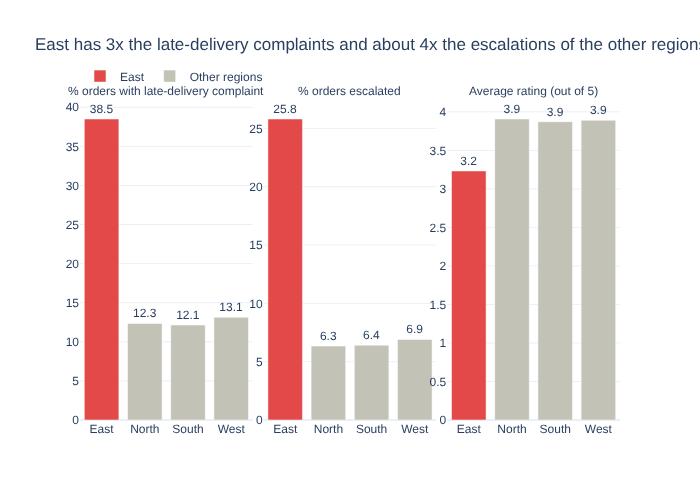

In [41]:
# CHART 3: region scorecard (three small panels, one measure each)
c3 = reg.reset_index().melt(id_vars="region_at_order", value_vars=["late_delivery_rate", "escalation_rate", "avg_rating"],
                            var_name="measure", value_name="value")
c3["measure"] = c3["measure"].map({"late_delivery_rate": "% orders with late-delivery complaint",
                                   "escalation_rate": "% orders escalated",
                                   "avg_rating": "Average rating (out of 5)"})
c3["highlight"] = np.where(c3["region_at_order"] == "East", "East", "Other regions")

fig3 = px.bar(c3, x="region_at_order", y="value", color="highlight", facet_col="measure",
              text=c3["value"].round(1),
              color_discrete_map={"East": RED, "Other regions": GREY},
              title="East has 3x the late-delivery complaints and about 4x the escalations of the other regions",
              labels={"region_at_order": "", "value": "", "highlight": ""},
              template="plotly_white")
fig3.update_yaxes(matches=None, showticklabels=True)
fig3.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig3.update_traces(textposition="outside")
fig3.update_layout(legend=dict(orientation="h", y=1.12, x=0))
save_chart(fig3, "chart3_east_region_service")
fig3.show()

In [42]:
# Is East a one-month blip or a permanent problem?
trend = df.pivot_table(index="month", columns="region_at_order", values="late_complaint", aggfunc="mean") * 100
trend.round(0)

region_at_order,East,North,South,West
month,,,,
1,42.00,13.00,15.00,18.00
2,45.00,16.00,15.00,8.00
3,40.00,10.00,13.00,13.00
4,42.00,17.00,10.00,6.00
5,27.00,10.00,8.00,25.00
6,43.00,9.00,13.00,6.00
7,39.00,14.00,13.00,6.00
8,45.00,11.00,11.00,15.00
9,35.00,9.00,12.00,20.00


In [43]:
# Even when East orders are NOT late, are customers more upset?
(df.pivot_table(index="region_at_order", columns="late_complaint", values="escalated", aggfunc="mean") * 100).round(1) \
    .rename(columns={False: "escalation % (no late complaint)", True: "escalation % (late complaint)"})

late_complaint,escalation % (no late complaint),escalation % (late complaint)
region_at_order,,
East,6.50,56.60
North,1.70,38.90
South,1.30,43.40
West,1.20,44.40


In [44]:
# Is it a channel or a supplier problem instead of a region problem?
print((df.pivot_table(index="region_at_order", columns="sales_channel", values="late_complaint", aggfunc="mean") * 100).round(0))
print()
print((df.groupby("supplier")["late_complaint"].mean() * 100).round(1).sort_values(ascending=False))

sales_channel     App  Marketplace  Store  Website
region_at_order                                   
East            37.00        48.00  39.00    36.00
North           13.00         6.00  17.00    11.00
South           11.00        12.00  16.00    11.00
West            14.00        16.00  15.00    10.00

supplier
Aruna         19.70
DigiKart      18.60
BharatWorks   17.80
Futura        16.50
Crescent      16.30
Ecomade       15.50
Name: late_complaint, dtype: float64


**What we found:**
- **East: 38.5%** of orders get a late-delivery complaint, vs **12-13%** in North, South and West.
- East is only **19% of orders but 48% of all escalations** (193 of 406). Its average rating is **3.23** vs about 3.9 elsewhere.
- It is high in **every month** (26-49%), across **every sales channel**, so it is a **permanent, region-level logistics problem**, not one bad month, one channel or one supplier (suppliers are all 15-20%).
- East also gets slightly **higher discounts** (15.9% avg vs ~13.5%). We cannot prove it from this data, but it could be goodwill discounts to calm unhappy customers, which would also cost margin.

### 3.2 Do bad experiences make customers stop buying?
We tested this because it is the real "so what". For each order, we measured how many days until that customer's next order.

In [45]:
seq = df[df["customer_id"] != "Unknown"].sort_values(["customer_id", "order_date", "order_id"]).copy()
seq["days_to_next_order"] = (seq.groupby("customer_id")["order_date"].shift(-1) - seq["order_date"]).dt.days

print(seq.groupby("complaint_category")["days_to_next_order"].agg(["median", "mean", "count"]).round(1))
print()
print("Avg orders per customer by region:")
print(cust.groupby("region")["orders"].mean().round(2))

                    median  mean  count
complaint_category                     
Damaged item         29.00 40.80    128
Difficult return     27.00 45.20    155
Late delivery        36.00 49.40    581
None                 32.00 45.00   2257
Poor quality         29.00 43.60    131
Wrong item           31.50 40.60    148

Avg orders per customer by region:
region
East    6.50
North   6.88
South   6.68
West    6.63
Name: orders, dtype: float64


**Honest result:** customers who complained still came back. The median gap after a late delivery is 36 days vs 32 days with no complaint, and East customers still place 6.5 orders a year vs 6.6-6.9 elsewhere. So **within one year of data we cannot prove that late delivery is causing customers to leave**. We are not going to claim it does.

**But it still matters because:**
1. Every escalation costs customer-service time and money. East creates almost half of them.
2. A 3.2 rating (vs 3.9) is visible to new customers on marketplaces and app stores. Remember from 2.4 that the company is barely acquiring new customers.
3. Customers who keep complaining but keep buying may be loyal only until a competitor delivers faster.

**Recommendation:** audit the East delivery set-up as a priority (partner, promised dates, warehouse distance). Get `delivery.csv` so the team can see which partner and which promised-vs-actual gap is behind this.

---
# Stage 4: OUR HIDDEN MYSTERY 🕵️
## "Where does the profit actually go, and is marketing earning its money?"

### 1. Question
The order data says Vyapaar made **₹48 lakh gross profit**. But that number ignores marketing. We asked: *after paying for the 18 marketing campaigns, how much is left, and can we prove the campaigns are bringing in the sales?*

To answer it we combined **orders + marketing**, which management didn't ask us to do directly.

In [46]:
list_value = (df["quantity"] * df["unit_price_inr"]).sum()
discounts = list_value - total_rev
product_cost = df["cost_inr"].sum()
mkt_spend = marketing_c["spend_inr"].sum()
left = total_profit - mkt_spend

print("Sales at list price:", lakh(list_value))
print("- Discounts given:", lakh(discounts))
print("= Revenue:", lakh(total_rev))
print("- Product cost:", lakh(product_cost))
print("= Gross profit:", lakh(total_profit))
print("- Marketing spend:", lakh(mkt_spend))
print("= Left after marketing:", lakh(left), f"({left / total_rev:.1%} of revenue)")
print("\nMarketing spend as % of gross profit:", f"{mkt_spend / total_profit:.0%}")

Sales at list price: ₹203.94 lakh
- Discounts given: ₹27.99 lakh
= Revenue: ₹175.95 lakh
- Product cost: ₹127.97 lakh
= Gross profit: ₹47.98 lakh
- Marketing spend: ₹46.99 lakh
= Left after marketing: ₹0.98 lakh (0.6% of revenue)

Marketing spend as % of gross profit: 98%


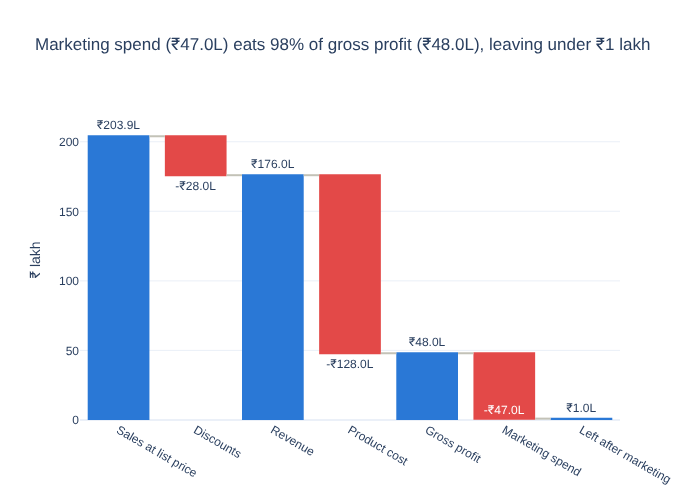

In [47]:
# CHART 4: profit waterfall
fig4 = go.Figure(go.Waterfall(
    x=["Sales at list price", "Discounts", "Revenue", "Product cost", "Gross profit", "Marketing spend", "Left after marketing"],
    measure=["absolute", "relative", "total", "relative", "total", "relative", "total"],
    y=[list_value / 1e5, -discounts / 1e5, 0, -product_cost / 1e5, 0, -mkt_spend / 1e5, 0],
    text=[f"-₹{abs(v):,.1f}L" if v < 0 else f"₹{v:,.1f}L" for v in [list_value / 1e5, -discounts / 1e5, total_rev / 1e5, -product_cost / 1e5,
                                   total_profit / 1e5, -mkt_spend / 1e5, left / 1e5]],
    textposition=["outside", "outside", "outside", "outside", "outside", "inside", "outside"],
    insidetextfont=dict(color="white"),
    decreasing=dict(marker=dict(color=RED)),
    increasing=dict(marker=dict(color=BLUE)),
    totals=dict(marker=dict(color=BLUE)),
    connector=dict(line=dict(color=GREY))))
fig4.update_layout(title="Marketing spend (₹47.0L) eats 98% of gross profit (₹48.0L), leaving under ₹1 lakh",
                   yaxis_title="₹ lakh", template="plotly_white", showlegend=False, yaxis_range=[0, 230])
save_chart(fig4, "chart4_profit_waterfall")
fig4.show()

That is a shocking number. Almost all of the gross profit is spent on marketing. (And this is **before** delivery costs, salaries, rent etc., which we do not have.) So the next question is: **is that marketing money actually bringing in the sales?**

In [48]:
tagged = df[df["campaign_id"] != "No campaign"].merge(marketing_c[["campaign_id", "start_date", "end_date"]], on="campaign_id")
tagged["timing"] = np.where(tagged["order_date"] < tagged["start_date"], "Before campaign started",
                            np.where(tagged["order_date"] > tagged["end_date"], "After campaign ended", "During campaign"))
timing = tagged["timing"].value_counts()
print(timing, "\n")
print((timing / timing.sum() * 100).round(1))

timing
Before campaign started    1215
After campaign ended       1030
During campaign             283
Name: count, dtype: int64 

timing
Before campaign started   48.10
After campaign ended      40.70
During campaign           11.20
Name: count, dtype: float64


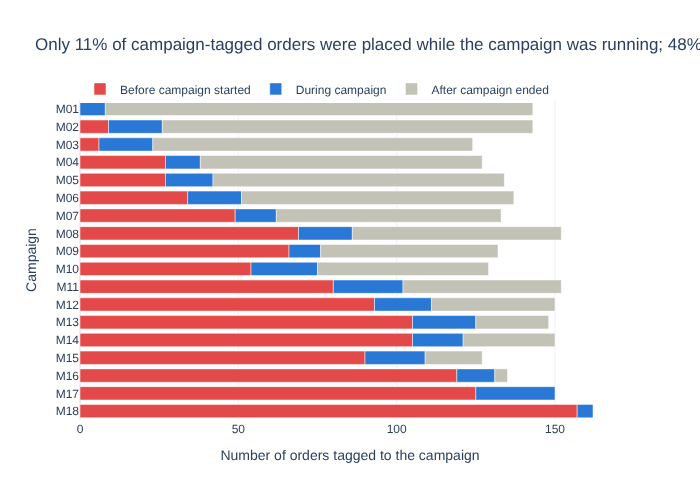

In [49]:
# CHART 5: when did campaign-tagged orders happen?
c5 = tagged.groupby(["campaign_id", "timing"]).size().reset_index(name="orders")
fig5 = px.bar(c5, y="campaign_id", x="orders", color="timing", orientation="h",
              category_orders={"timing": ["Before campaign started", "During campaign", "After campaign ended"],
                               "campaign_id": sorted(c5["campaign_id"].unique())},
              color_discrete_map={"Before campaign started": RED, "During campaign": BLUE, "After campaign ended": GREY},
              title="Only 11% of campaign-tagged orders were placed while the campaign was running; 48% came BEFORE it started",
              labels={"campaign_id": "Campaign", "orders": "Number of orders tagged to the campaign", "timing": ""},
              template="plotly_white")
fig5.update_layout(legend=dict(orientation="h", y=1.08, x=0), bargap=0.25)
save_chart(fig5, "chart5_campaign_tag_timing")
fig5.show()

In [50]:
# Do tagged orders go up when a campaign spends more, or reports more conversions?
camp = (tagged.groupby("campaign_id").agg(tagged_orders=("order_id", "count"), tagged_revenue=("revenue_inr", "sum"))
        .join(marketing_c.set_index("campaign_id")[["channel", "spend_inr", "conversions"]]))
print("Correlation spend vs tagged orders:", round(camp["spend_inr"].corr(camp["tagged_orders"]), 2))
print("Correlation reported conversions vs tagged orders:", round(camp["conversions"].corr(camp["tagged_orders"]), 2))
camp.sort_values("spend_inr", ascending=False)

Correlation spend vs tagged orders: 0.19
Correlation reported conversions vs tagged orders: -0.35


,tagged_orders,tagged_revenue,channel,spend_inr,conversions
campaign_id,,,,,
M07,133,"644,695.47",Social Media,413129,373
M08,152,"597,496.47",Search Ads,410288,118
M18,162,"626,601.90",Outdoor,377932,33
M13,148,"632,454.96",Social Media,373034,534
M09,132,"488,150.13",Email,340036,482
M01,143,"597,830.51",Social Media,336420,138
M10,129,"639,310.36",Influencer,335202,346
M16,135,"612,732.59",Influencer,312597,96
M17,150,"714,343.32",Affiliate,295962,370


In [51]:
# Marketing says it converted this many people. How many customers do we actually have?
print("Conversions reported by marketing (18 campaigns):", marketing_c["conversions"].sum())
print("Total customers in the whole order data:", cust.shape[0])
print("Orders tagged to any campaign:", len(tagged))

h2_spend = marketing_c.loc[marketing_c["start_date"] >= "2025-07-01", "spend_inr"].sum()
h2_conv = marketing_c.loc[marketing_c["start_date"] >= "2025-07-01", "conversions"].sum()
h2_new = (cust["first_order"] >= "2025-07-01").sum()
print(f"\nCampaigns launched in H2 2025: spend {lakh(h2_spend)}, reported conversions {h2_conv}, actual NEW customers in H2: {h2_new}")

Conversions reported by marketing (18 campaigns): 4309
Total customers in the whole order data: 599
Orders tagged to any campaign: 2528

Campaigns launched in H2 2025: spend ₹20.75 lakh, reported conversions 1596, actual NEW customers in H2: 15


### 2. Evidence
1. **Marketing (₹47.0 lakh) = 98% of gross profit (₹48.0 lakh).** After marketing, only about **₹1 lakh** is left on ₹176 lakh of revenue (0.6%).
2. **The campaign tag on orders is not believable:** 48% of tagged orders were placed **before** the campaign even started and only **11%** during it. Every campaign gets roughly the same number of tagged orders (124-162) whatever it spends (correlation with spend = 0.19).
3. **Marketing's own "conversions" don't match the orders:** campaigns report **4,309 conversions**, but the company only has **599 customers**. Campaigns launched in H2 spent **₹20.75 lakh** and reported **1,596 conversions**, yet only **15 new customers** placed a first order in H2.

### 3. Business significance
- Management thinks the profit pressure comes from products and discounts. Those matter, but **the biggest single cost after the product itself is marketing**, and **nobody can currently prove it is working**.
- Since **99% of customers are repeat buyers**, a lot of these "conversions" may be loyal customers who would have bought anyway.
- *Assumptions:* we assumed all campaign spend relates to 2025 sales (M17/M18 run a few weeks into Jan 2026). We also don't know exactly how marketing defines a "conversion". Even with generous assumptions, the gap is far too big to explain away.

### 4. Recommendation
1. **Fix the tracking before spending more:** use a unique coupon code / UTM link per campaign, and make the system reject a campaign tag if the order date is outside the campaign dates.
2. **Define a conversion as "first order by a new customer"** so marketing and finance count the same thing.
3. **Run a simple test:** pause one channel (e.g. Outdoor) in one region for a month and compare sales with similar regions. If sales don't drop, the spend wasn't adding much.
4. Until then, **cut the weakest spend first** (see Bonus section below).

---
# Bonus: Marketing Mystery 📣
We use marketing's **own reported numbers** here (keeping in mind the doubts above). Even by its own numbers, some channels look very weak.

In [52]:
ch = marketing_c.groupby("channel").agg(campaigns=("campaign_id", "count"), spend=("spend_inr", "sum"),
                                        leads=("leads", "sum"), conversions=("conversions", "sum"))
ch["lead_to_conversion_%"] = ch["conversions"] / ch["leads"] * 100
ch["cost_per_lead"] = ch["spend"] / ch["leads"]
ch["cost_per_conversion"] = ch["spend"] / ch["conversions"]
ch["share_of_spend_%"] = ch["spend"] / ch["spend"].sum() * 100
ch["share_of_conversions_%"] = ch["conversions"] / ch["conversions"].sum() * 100
ch.sort_values("cost_per_conversion").round(1)

,campaigns,spend,leads,conversions,lead_to_conversion_%,cost_per_lead,cost_per_conversion,share_of_spend_%,share_of_conversions_%
channel,,,,,,,,,
Affiliate,3,604009,12709,941,7.40,47.50,641.90,12.90,21.80
Email,3,799396,7206,988,13.70,110.90,809.10,17.00,22.90
Influencer,3,729094,11986,714,6.00,60.80,"1,021.10",15.50,16.60
Social Media,3,1122583,13786,1045,7.60,81.40,"1,074.20",23.90,24.30
Search Ads,3,713260,6436,510,7.90,110.80,"1,398.50",15.20,11.80
Outdoor,3,731145,5720,111,1.90,127.80,"6,586.90",15.60,2.60


In [53]:
# Check the given cost_per_conversion column against our own calculation
print("Rows where cost_per_conversion doesn't match spend/conversions:",
      (abs(marketing_c["spend_inr"] / marketing_c["conversions"] - marketing_c["cost_per_conversion_inr"]) > 0.05).sum())
print("Average gross profit per order:", f"₹{df['profit_inr'].mean():,.0f}")
print("Average gross profit per customer per year:", f"₹{cust['profit'].mean():,.0f}")
marketing_c.sort_values("cost_per_conversion_inr", ascending=False)[["campaign_id", "channel", "spend_inr", "leads", "conversions", "cost_per_conversion_inr"]].head(5)

Rows where cost_per_conversion doesn't match spend/conversions: 0
Average gross profit per order: ₹1,199
Average gross profit per customer per year: ₹8,008


,campaign_id,channel,spend_inr,leads,conversions,cost_per_conversion_inr
17,M18,Outdoor,377932,1581,33,"11,452.48"
11,M12,Outdoor,126587,1210,20,"6,329.35"
5,M06,Outdoor,226626,2929,58,"3,907.34"
7,M08,Search Ads,410288,1315,118,"3,477.02"
15,M16,Influencer,312597,1783,96,"3,256.22"


**So what? (marketing)**
- **Outdoor** costs **₹6,587 per conversion**, about **10× Affiliate (₹642)**. It takes **15.6% of the budget** but delivers only **2.6% of conversions**. M18 (Outdoor) cost **₹11,452 per conversion**, more than the **₹8,008 gross profit an average customer generates in a whole year**.
- **Lots of leads ≠ success:** Influencer and Social Media bring lots of leads, but only 6-8% convert. **Email** converts 14% of leads, the best of any channel.
- **This is NOT an ROI calculation.** A real ROI needs the profit each campaign truly caused, and Stage 4 showed the order data can't tell us that. What we can say is that Outdoor's cost per conversion is far above the profit one order (₹1,200) or even one customer-year (₹8,008) brings in.
- **Recommendation:** move Outdoor budget to Email/Affiliate, and judge every channel on cost per *new paying customer* once tracking is fixed.

---
# Management Summary 🎯
*3 findings + 3 evidence-based charts + 3 actions, plus our hidden mystery.*

### Finding 1: Electronics sells, but it barely makes money
- **Evidence:** Electronics = 14.5% of revenue but only 3.2% of profit (6.1% margin vs 27% company average). 237 of 809 Electronics orders lost money. Its mark-up is only 1.22× cost, so margin turns negative at a 20% discount. *(Chart 1, Chart 2)*
- **Business implication:** Electronics is using up discount budget and effort for very little profit. Beauty (45% of profit, 41% margin) is the real profit engine.
- **Recommended action:** cap Electronics discounts at 10% (worth about ₹1.5 lakh extra profit a year, roughly doubling the category's profit) and renegotiate Electronics supplier costs. Push promotions towards Beauty instead.

### Finding 2: Deep discounts are giving away profit without increasing sales
- **Evidence:** average units per order stay flat (1.77 at 0% → 1.69 at 40%; correlation −0.01), while profit per order falls from ₹1,915 to −₹33. Orders at 30-40% off = 18% of orders but only 3.5% of profit. ₹28 lakh was given away in discounts, more than half of gross profit. *(Chart 2)*
- **Business implication:** the current discount strategy is not supported by the evidence. It mainly cuts the price for customers who would have bought anyway.
- **Recommended action:** set a maximum discount per category based on its mark-up (no 40% discounts on any category; Electronics max 10%; Home & Kitchen / Office / Sports max 20%). Test any deeper discount on a small group first.

### Finding 3: The East region has a delivery problem that is hurting ratings
- **Evidence:** 38.5% of East orders get a late-delivery complaint vs 12-13% elsewhere, in every month and every channel. East = 19% of orders but 48% of all escalations; rating 3.23 vs ~3.9. Late delivery is the complaint with the worst rating (2.43) and highest escalation rate (48%). *(Chart 3)*
- **Business implication:** in a business where 99% of customers come back, the customer experience is the asset. Escalations cost service money, and low ratings make it harder to win new customers. We could not prove customers are leaving yet, so this is the moment to fix it, before they do.
- **Recommended action:** audit the East delivery partner(s) and promised delivery dates within 30 days. Set an on-time delivery target for East and review it monthly. Share `delivery.csv` with the analytics team to find the root cause.

### OUR HIDDEN MYSTERY: Marketing eats 98% of gross profit, and we can't prove it works
- **Question:** after marketing, how much profit is left, and are the campaigns really driving sales?
- **Evidence:** ₹47.0 lakh of marketing spend vs ₹48.0 lakh of gross profit leaves under ₹1 lakh. Only 11% of campaign-tagged orders happened while the campaign was running (48% before it started). Marketing reports 4,309 conversions, but there are only 599 customers, and only 15 new customers joined in H2 despite ₹20.75 lakh of H2 campaign spend. *(Chart 4, Chart 5)*
- **Implication:** marketing is the biggest controllable cost and is currently unmeasured.
- **Recommendation:** fix campaign tracking (coupon/UTM + date validation), define a conversion as a new customer's first order, run a pause test on Outdoor, and move Outdoor budget (₹6,587 per conversion vs ₹642 for Affiliate) to Email/Affiliate.

### Limitations (what we could not check)
- `customers.csv` and `delivery.csv` were not in our folder. So: no age/segment/joining analysis, and no delivery partner or promised-vs-actual delay analysis. We used `region_at_order` and the "Late delivery" complaint as proxies.
- Gross profit = revenue − product cost only. Shipping, returns, staff and rent costs are not in the data, so the real "left after marketing" is probably lower still.
- One year of data only, so we cannot see long-term churn.

In [54]:
print("Charts saved:")
for f in sorted(os.listdir(CHARTS)):
    print("  ", f)
print("\nCleaned data saved:", os.listdir(f"{DATA}/cleaned"))

Charts saved:
   chart1_category_revenue_vs_profit.html
   chart1_category_revenue_vs_profit.png
   chart2_discount_vs_margin.html
   chart2_discount_vs_margin.png
   chart3_east_region_service.html
   chart3_east_region_service.png
   chart4_profit_waterfall.html
   chart4_profit_waterfall.png
   chart5_campaign_tag_timing.html
   chart5_campaign_tag_timing.png

Cleaned data saved: ['cleaning_log.csv', 'vyapaar_master_clean.csv']
